In [1]:
import ast
import os
import optuna
import ipynbname
import pandas as pd
import numpy as np
from optuna.exceptions import TrialPruned
from Functions.AutoCloud_V5 import *
from Functions.Utils import *
from Functions.Graphs import *
from Functions.TedaGraphs import *
from Functions.Utils_OPT_R2 import *

FileName = ipynbname.name()

# Configuração do experimento
FEEDBACK = 'symmetric'      # 'symmetric' (gradiente no passo atual) ou 'random' (ablação: RFLO + DFA)
WTAG, WTAP = False, False   # configuração principal: soma ponderada dos grânulos (eq. 36)
EOL = 0.3                   # limiar de fim de vida (EoL) do HI

def RunTag(feedback=None, wtaG=None, wtaP=None):
    # Uma pasta de resultados por configuração (feedback, wtaG, wtaP)
    feedback = FEEDBACK if feedback is None else feedback
    wtaG = WTAG if wtaG is None else wtaG
    wtaP = WTAP if wtaP is None else wtaP
    return f'{FileName}_{feedback}_G{int(wtaG)}P{int(wtaP)}'

def RefEoL(sig, eol, nI, mO, mode):
    '''
    Referência da RUL real baseada no limiar de EoL (eq. 12): RUL_real = iEoL - k_dado.
    O AutoCloud calcula rulR = ref - k, com k = j + 2 na iteração j, e o PrepareData
    alinha a iteração j à amostra k_dado = k0 + j. Logo ref = iEoL - k0 + 2.
    Retorna ref e J, o número de iterações com RUL real >= 1.
    '''
    sig = np.asarray(sig, dtype=float)
    if not np.any(sig <= eol): raise ValueError('O HI nunca atinge o limiar de EoL.')
    iEoL = int(np.argmax(sig <= eol))
    k0 = (max(nI, 1, mO) if mode in ('ahead', 1) else max(nI, 1)) - 1
    return iEoL - k0 + 2, iEoL - k0

def nOMax(sig, eol):
    '''
    Maior nO (modo 'ahead') para o qual o fluxo do PrepareData alcança a última amostra antes do EoL.
    A última janela fica em k = K - nO - 2 (o PrepareData descarta a última); exigir k >= iEoL - 1
    dá nO <= K - iEoL - 1, independente de nI e mO. No modo 'past' o fluxo sempre alcança o EoL.
    '''
    sig = np.asarray(sig, dtype=float)
    return len(sig) - int(np.argmax(sig <= eol)) - 1

out_path = os.path.join('Optimization', RunTag(), 'multi', 'Optimization.csv')
dfs = [pd.read_csv(out_path)] if os.path.exists(out_path) else []
RS = pd.read_excel(r'Dataset\RS.xlsx')
HI = pd.read_excel(r'Dataset\HI.xlsx')
sig = HI['PC1'].values

c:\Users\Usuario\Desktop\Python\Batteries_Prognostics\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


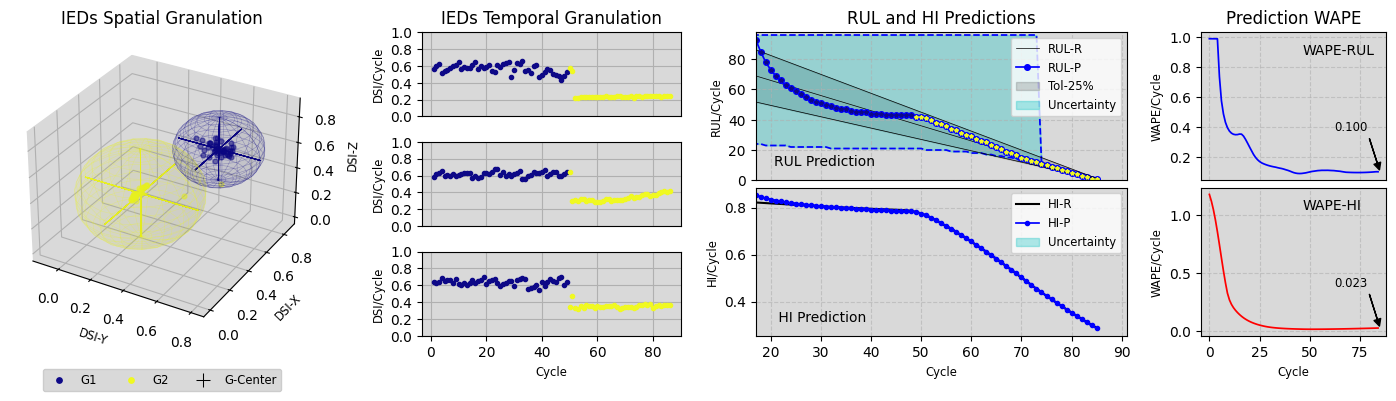

In [2]:
# Teste rápido (smoke test): parâmetros ajustados no R07 para a regra antiga (DRTLO_GD_R2).
# Não são válidos para o eRNN_GD_R2; os parâmetros finais devem vir de uma nova busca (Optimize).
params = [3.5,28,[70],8,0,1,2,5,19,1,0]

m,nI,nR,nO,mO,N1,N2,N3,τ,mode,act = params
X, Y, Z = PrepareData(RS, HI, nI, nO, mO, 1, mode)
ref, J = RefEoL(sig, EOL, nI, mO, mode)
if len(X) < J: print(f'Aviso: nO={nO} > {nOMax(sig, EOL)}: o fluxo termina antes do EoL (última RUL real = {J-len(X)+1}).')
nI = len(Y[0])
if isinstance(nR, str): nR = ast.literal_eval(nR)

teda=AutoCloud(m=m,nI=nI,nR=nR,nO=nO+mO,ηS=[N1,N2,N3],mode=mode,act=act,
               tau=τ,rho=1e-4,eol=EOL,ref=ref,wtaG=WTAG,wtaP=WTAP,feedback=FEEDBACK,mO=mO) 


for j,_ in enumerate(X[:J]):
    teda.run(X[j])
    teda.RUL_Prediction(Y[j],mode='interval',lim=len(sig)-nI+1,show=False)
    teda.WAPE_HI2(Y[j],Z[j])
    teda.Adapt(Y[j],Z[j])

#teda.c = np.append(teda.c,teda.gm)  
PlotDSI_3D_PLT(teda)


In [2]:
def Optimize(
        FileName=None,OptDim=None,OptSampler=None,OptSeed=None,OptPrune=False,
        n_study=None,timeout=None,n_trials=None,
        patience=None,
        mS =None,nIS=None,nLS=None,nRS=None,nOS =None,mOS=None,
        N1S=None,N2S=None,N3S=None,τS =None,mdS=None,actS=None,
        feedback=None,wtaG=None,wtaP=None,
        OptReset=False,OptWarm=False,n_best=5):

    '''
        OptSampler modes available: None, Auto, GP, NSGAII, Random, TPE
    
        None: sampler default, suport multivariate optimization

        GP: suport multivariate optimization

        Auto: suport multivariate optimization
        
        NSGAII: poorly suport multivariate optimization
        
        Random: poorly suport multivariate optimization

        TPE: suport multivariate optimization

        feedback, wtaG, wtaP: model configuration (defaults: FEEDBACK, WTAG, WTAP from cell 0).
        Results are saved in Optimization/<FileName>_<feedback>_G<wtaG>P<wtaP>/.

        Persistent storage (SQLite, Optimization/<...>/optuna.db):
            each of the n_study sessions is an independent study named obj<1|2>_L<nLS[0]>-<nLS[1]>_s<i>,
            resumed on every execution (n_trials = number of NEW trials per execution).
        OptReset: delete and recreate the studies of these sessions (use after changing the objective/code).
        OptWarm : enqueue the best trial of the other sessions of the same configuration before optimizing.
        OptSeed : base seed; session i uses OptSeed + i (sessions stay independent).
        n_best  : rows kept per number of layers (nL) in Optimization.csv. The table is rebuilt from ALL
                  trials stored in the database (all sessions/phases), keeping the n_best smallest errors
                  of distinct parameter sets per nL; rows are grouped by nL (worst -> best within each group).
    '''

    if feedback is None: feedback = FEEDBACK
    if wtaG is None: wtaG = WTAG
    if wtaP is None: wtaP = WTAP
    FileName = f'{FileName}_{feedback}_G{int(wtaG)}P{int(wtaP)}'

    if OptDim == 1 or OptDim is None: SingleObj = True
    elif OptDim > 1: SingleObj = False    
    if n_study is None: n_study = 1
    if timeout is None: timeout = 60
    if n_trials is None and patience is None: n_trials = 25
    if patience is None:
        if n_trials < 0.5e4: patience = 500
        else: patience = int(0.02*n_trials)

    if mS  is None: mS  = [1.75,4.25]
    if nIS is None: nIS = [2,40]
    if nLS is None: nLS = [1,5]
    if nRS is None: nRS = [1,60]
    if nOS is None: nOS = [1,40]
    if mOS is None: mOS = [0,40]
    if N1S is None: N1S = [1,9]
    if N2S is None: N2S = [1,9]
    if N3S is None: N3S = [1,9]
    if τS  is None: τS  = [1,25]
    if mdS is None: mdS = [0,1]
    if actS is None: actS = [0,1,2]

    # Limita nO para que o fluxo sempre alcance o EoL: a RUL é avaliada até a última amostra antes
    # do EoL em todos os trials (evita favorecer nO grande, que encurta o trecho avaliado)
    if mdS[1] == 1:
        nOS = [nOS[0], min(nOS[1], nOMax(sig, EOL))]
        if nOS[0] > nOS[1]: raise ValueError(f'nOS inválido: o limite para alcançar o EoL é nO <= {nOMax(sig, EOL)}.')
        print(f'nO limitado a {nOS} para que o fluxo alcance o EoL.')

    if SingleObj: names = ['MAPE_RUL+MAPE_HI', 'm', 'nI', 'nR', 'nO', 'mO', 'N1', 'N2', 'N3','TAU','past/ahead','activation']
    else: names = ['MAPE_RUL','MAPE_HI', 'm', 'nI', 'nR', 'nO', 'mO', 'N1', 'N2', 'N3','TAU','past/ahead','activation']
    study_dir, out_path = df_ParamsTable(names,FileName)

    # Armazenamento persistente: um banco SQLite por configuração; cada sessão é um estudo independente e retomável
    db_path = os.path.abspath(os.path.join('Optimization', FileName, 'optuna.db'))
    storage = optuna.storages.RDBStorage('sqlite:///' + db_path.replace(os.sep, '/'))
    base_name = f'obj{1 if SingleObj else 2}_L{nLS[0]}-{nLS[1]}'
    Score = lambda t: t.value if SingleObj else sum(t.values)
    Complete = lambda st: [t for t in st.trials if t.state == optuna.trial.TrialState.COMPLETE]
    summary = []

    for i in range(n_study):
        study_name = f'{base_name}_s{i+1}'
        print(f'iteration: {i+1} | study: {study_name}')
        if OptReset and study_name in optuna.get_all_study_names(storage):
            optuna.delete_study(study_name=study_name, storage=storage)
            print(f'  {study_name}: estudo anterior apagado (OptReset=True).')

        def objective(trial):
            m = trial.suggest_float('m', mS[0], mS[1],step=0.25)
            nI = trial.suggest_int('nI', nIS[0], nIS[1]) 
            n_layers = trial.suggest_int('n_layers', nLS[0], nLS[1])
            nR = [trial.suggest_int(f'nR_layer_{l}', nRS[0], nRS[1]) for l in range(n_layers)]
            nO = trial.suggest_int('nO', nOS[0], nOS[1]) 
            N1 = trial.suggest_int('N1', N1S[0], N1S[1])
            N2 = trial.suggest_int('N2', N2S[0], N2S[1])
            N3 = trial.suggest_int('N3', N3S[0], N3S[1])
            τ = trial.suggest_int('τ', τS[0], τS[1])
            mode = trial.suggest_int('mode', mdS[0], mdS[1])  
            act = trial.suggest_int('act', actS[0], actS[1])  

            # Limites de nI e nO controlados apenas por nIS e nOS
            if mode == 'past' or mode == 0:
                mO = trial.suggest_int('mO', 0, 0) 
                if nO > nI: raise TrialPruned()

            elif mode == 'ahead' or mode == 1:
                mO = trial.suggest_int('mO', mOS[0], mOS[1]) 
                if mO > nI: raise TrialPruned()
                
            X, Y, Z = PrepareData(RS, HI, nI, nO, mO, 1, mode)
            ref, J = RefEoL(sig, EOL, nI, mO, mode)
            if len(X) < J: raise TrialPruned()   # o fluxo não alcança o EoL (não deve ocorrer com nOS limitado)
            
            # Ajuste com 'single': a predição pontual é idêntica à de 'interval' (rho só define os limites)
            teda=AutoCloud(m=m,nI=len(Y[0]),nR=nR,nO=nO+mO,ηS=[N1,N2,N3],mode=mode,act=act,
                           tau=τ,rho=0.0,eol=EOL,ref=ref,wtaG=wtaG,wtaP=wtaP,feedback=feedback,mO=mO) 
            for j,_ in enumerate(X[:J]):
                teda.run(X[j])
                teda.RUL_Prediction(Y[j],mode='single',lim=len(sig)-nI+1)
                teda.Adapt(Y[j],Z[j])
                #teda.WAPE_HI2(Y[j],Z[j])

                if np.isinf(teda.hiP[-1]) or np.isnan(teda.hiP[-1]): raise TrialPruned()
                if not OptPrune: continue
        
                if j >=40 and j%5==0:
                    if teda.wape_RUL > 0.6: raise TrialPruned()
                    if teda.wape_HI  > 0.3: raise TrialPruned()

                if SingleObj and j%35==0:
                    trial.report(teda.wape_RUL+teda.wape_HI, j)
                    if trial.should_prune():
                        raise optuna.TrialPruned()

            if SingleObj: return teda.wape_RUL + teda.wape_HI
            else: return teda.wape_RUL,teda.wape_HI

        # Sessões independentes: sementes distintas quando OptSeed é informado
        seed = None if OptSeed is None else OptSeed + i
        pruner=optuna.pruners.HyperbandPruner()
        if SingleObj: study = optuna.create_study(study_name=study_name,storage=storage,load_if_exists=True,
                                                  direction='minimize',pruner=pruner,sampler=SelSampler(mode=OptSampler,seed=seed))
        else: study = optuna.create_study(study_name=study_name,storage=storage,load_if_exists=True,
                                          directions=['minimize','minimize'],sampler=SelSampler(mode=OptSampler,seed=seed))
        n_prev, done = len(study.trials), Complete(study)

        if OptWarm:
            # Começa pelo melhor trial das outras sessões desta configuração
            others = [n for n in optuna.get_all_study_names(storage) if n.startswith(base_name + '_s') and n != study_name]
            cand = [t for n in others for t in Complete(optuna.load_study(study_name=n, storage=storage))]
            if cand:
                best = min(cand, key=Score)
                study.enqueue_trial(best.params, skip_if_exists=True)
                print(f'  OptWarm: melhor trial das outras sessões enfileirado (score {Score(best):.4f}).')

        # Parada antecipada conta trials sem superar o melhor resultado já armazenado
        # Contexto exibido acima de BEST TRIAL: nº de camadas, sessão, estudo, configuração e progresso
        callback = EarlyStoppingCallback(patience=patience, context={
            'nL': nLS, 'session': i+1, 'n_study': n_study, 'study_name': study_name, 'config': FileName,
            'n_prev': n_prev, 'n_trials': n_trials, 'timeout': timeout,
            'storage': storage, 'prefix': f'obj{1 if SingleObj else 2}_'})   # melhor trial por nL (todas as sessões/fases)
        if done:
            best_prev = min(done, key=Score)
            callback.best_score = Score(best_prev)
            callback.best_number = best_prev.number
            callback.best_trial_info = f'Trial #{best_prev.number:03d} (sessões anteriores) | Score: {Score(best_prev):.4f} | Params: {best_prev.params}'
        print(f'  {study_name}: {n_prev} trials armazenados' + (f', melhor {callback.best_score:.4f}' if done else ''))
        study.optimize(objective, n_trials=n_trials, timeout=timeout, callbacks=[callback])

        done = Complete(study)
        summary.append((study_name, n_prev, len(study.trials), min(map(Score, done)) if done else float('nan')))

    print('\nResumo das sessões (banco: ' + db_path + ')')
    for name, n0, n1, best in summary:
        print(f'  {name}: {n0} -> {n1} trials | melhor {best:.4f}')

    # Tabela de resultados reconstruída do banco: todos os trials concluídos deste tipo de objetivo
    # (todas as sessões, fases e nº de camadas), mantendo para cada nL os n_best menores erros
    rows = []
    for name in optuna.get_all_study_names(storage):
        if not name.startswith(f'obj{1 if SingleObj else 2}_'): continue
        for t in Complete(optuna.load_study(study_name=name, storage=storage)):
            p = t.params
            nR_list = [p[f'nR_layer_{l}'] for l in range(p['n_layers'])]
            prm = [p['m'],p['nI'],str(nR_list),p['nO'],p['mO'],p['N1'],p['N2'],p['N3'],p['τ'],p['mode'],p['act']]
            rows.append(list(t.values[:1 if SingleObj else 2]) + prm + [p['n_layers']])
    df_all = pd.DataFrame(rows, columns=names + ['_nL'])
    df_all['_err'] = df_all[names[0]] if SingleObj else df_all[names[0]] + df_all[names[1]]
    # Mesmo conjunto de parâmetros conta uma vez (mantém o menor erro)
    df_all = df_all.sort_values('_err').drop_duplicates(subset=names[1 if SingleObj else 2:])
    df_stdy = df_all.groupby('_nL', group_keys=False).head(n_best)
    df_stdy = df_stdy.sort_values(['_nL', '_err'], ascending=[True, False])

    print(f'\nOptimization.csv: {n_best} melhores por nº de camadas ({out_path})')
    for nL_, grp in df_stdy.groupby('_nL'):
        print(f'  nL={nL_}: {len(grp)} linhas | melhor {grp["_err"].min():.4f} | pior mantido {grp["_err"].max():.4f}')

    df_stdy = df_stdy.drop(columns=['_nL', '_err']).reset_index(drop=True)
    df_stdy.to_csv(out_path, index=False)
    return df_stdy

#Fase 1 – exploração: TPE padrão, 3 reinícios independentes por nº de camadas.\
#OptReset=True só na PRIMEIRA execução (apaga estudos antigos de código/faixas anteriores); depois remova.


In [4]:
lS,lE = 3,4
for nL in range(lS,lE+1):
    df = Optimize(FileName=FileName, OptDim=1, OptSampler='random', OptSeed=100*nL, OptPrune=False,
                  n_study=3, n_trials=2.5e3, timeout=3600, patience=1500,
                  mS=[2.0,4.5], nLS=[nL,nL], nRS=[1,70], nOS=[1,9], mOS=[0,10], mdS=[0,1], actS=[0,1],
                  feedback=FEEDBACK, wtaG=WTAG, wtaP=WTAP, OptReset=True)

OPTIMIZATION PROGRESS
Layers (nL): 4  |  Session: 3/3 (obj1_L4-4_s3)  |  Sampler: Random  |  Config: TedaRNN_R01_symmetric_G0P0
Trials in this study: 0 stored before this run  |  This run: 2500/2500  |  Elapsed: 00:10:18 / 01:00:00

BEST TRIAL PER nL
nL=3 | obj1_L3-3_s3 #0169 | Score: 0.1421 | Params: {'m': 3.0, 'nI': 36, 'n_layers': 3, 'nR_layer_0': 52, 'nR_layer_1': 28, 'nR_layer_2': 46, 'nO': 9, 'N1': 1, 'N2': 3, 'N3': 5, 'τ': 15, 'mode': 1, 'act': 0, 'mO': 3}
nL=4 | obj1_L4-4_s1 #1320 | Score: 0.1290 | Params: {'m': 2.75, 'nI': 30, 'n_layers': 4, 'nR_layer_0': 22, 'nR_layer_1': 17, 'nR_layer_2': 9, 'nR_layer_3': 54, 'nO': 4, 'N1': 1, 'N2': 3, 'N3': 3, 'τ': 21, 'mode': 0, 'act': 0, 'mO': 0}   <-- running
Current session best: #2460 | Score: 0.1437

LAST 3 TRIALS
Trial #2497 [COMPLETE] | Score: 2.7707 | Params: {'m': 4.25, 'nI': 19, 'n_layers': 4, 'nR_layer_0': 66, 'nR_layer_1': 36, 'nR_layer_2': 61, 'nR_layer_3': 69, 'nO': 8, 'N1': 4, 'N2': 6, 'N3': 4, 'τ': 3, 'mode': 0, 'act': 0, '

#Fase 2 – refinamento: GP continua os MESMOS estudos (usa todos os trials da fase 1).

In [ ]:
for nL in range(lS,lE+1):
    df = Optimize(FileName=FileName, OptDim=1, OptSampler='tpe', OptSeed=100*nL, OptPrune=True,
                n_study=1, n_trials=2.5e3, timeout=3600, patience=500,
                mS=[2.0,4.5], nLS=[nL,nL], nRS=[1,70], nOS=[1,9], mOS=[0,10], mdS=[0,1], actS=[0,1],
                feedback=FEEDBACK, wtaG=WTAG, wtaP=WTAP)


Phase 3 — analysis (new cell):




In [ ]:
db = 'sqlite:///' + os.path.abspath(os.path.join('Optimization', RunTag(), 'optuna.db')).replace(os.sep, '/')
for name in sorted(optuna.get_all_study_names(db)):
    st = optuna.load_study(study_name=name, storage=db)
    done = [t for t in st.trials if t.state == optuna.trial.TrialState.COMPLETE]
    best = f'{min(t.value for t in done):.4f}' if done else '-'
    print(f'{name}: {len(st.trials)} trials | {len(done)} completos | melhor {best}')

st = optuna.load_study(study_name='obj1_L2-2_s1', storage=db)   # escolha o estudo
optuna.visualization.plot_optimization_history(st).show()
optuna.visualization.plot_param_importances(st).show()
optuna.visualization.plot_slice(st).show()

In [ ]:
OptPath = os.path.join('Optimization', RunTag(), 'mono', 'Optimization.csv')   # pasta do R09 (configuração atual)
df = pd.read_csv(OptPath,)
#df = df[(df.iloc[:,0] <= 0.07)]
NL_SEL = None   # None: melhor resultado global; int: melhor resultado com esse nº de camadas
nLs = df['nR'].apply(lambda r: len(ast.literal_eval(r)))
sel = df if NL_SEL is None else df[nLs == NL_SEL]
best = sel.loc[[sel.iloc[:, 0].idxmin()]]
params_list = pd.concat([df.drop(best.index), best]).values[:,-11:]   # última linha = selecionada (usada na célula seguinte)
df

In [ ]:
tedas = []
for i,params in enumerate(params_list[-1:]):
    m,nI,nR,nO,mO,N1,N2,N3,τ,mode,act = params
    X, Y, Z = PrepareData(RS, HI, nI, nO, mO, 1, mode)
    ref, J = RefEoL(sig, EOL, nI, mO, mode)
    if len(X) < J: print(f'Aviso: nO={nO} > {nOMax(sig, EOL)}: o fluxo termina antes do EoL (última RUL real = {J-len(X)+1}).')
    if isinstance(nR, str): nR = ast.literal_eval(nR)

    # 'interval': a predição pontual (e as métricas) é idêntica à do ajuste com 'single'; rho define apenas os limites
    teda=AutoCloud(m=m,nI=len(Y[0]),nR=nR,nO=nO+mO,ηS=[N1,N2,N3],mode=mode,act=act,
                tau=τ,rho=0.01,eol=EOL,ref=ref,wtaG=WTAG,wtaP=WTAP,feedback=FEEDBACK,mO=mO) 
    for j,_ in enumerate(X[:J]):
        teda.run(X[j])
        teda.RUL_Prediction(Y[j],mode='interval',lim=len(sig)-nI+1,show=False)
        teda.Adapt(Y[j],Z[j])

    teda.c = np.append(teda.c,teda.gm)  
    tedas.append(teda)
    #PlotSeriesPLY(ySeries=[teda.wape_HI_hist,teda.wape_RUL_hist])

In [ ]:
tedaRef = tedas[0]
tedaRef.RUL_Granularity()
print(tedaRef.cov,tedaRef.sp,tedaRef.V)
PlotDSI_3D_PLT(tedaRef, w=18,h=6)

In [ ]:
# Verificação: grânulos não devem compartilhar (nem ter idênticos) os pesos da RNN
granulos = [c for c in teda.c if c.ID != 'GM']
for a in range(len(granulos)):
    for b in range(a+1, len(granulos)):
        ra, rb = granulos[a].rnn, granulos[b].rnn
        iguais = [bool(np.allclose(ra.wI[l], rb.wI[l]) and np.allclose(ra.wR[l], rb.wR[l])) for l in range(ra.nL)]
        print(f'G{granulos[a].ID} x G{granulos[b].ID} | pesos idênticos por camada: {iguais} | '
              f'wO idêntico: {np.allclose(ra.wO, rb.wO)} | mesmo objeto: {ra.wO is rb.wO}')


In [ ]:
for cloud in teda.c:
    print(cloud.ID, cloud.rnn.wR[0][1][-1])